# Biological class relations in IMSTE and UMAP

This notebook compares 2D class-mixture graphs from IMSTE and UMAP on mouse myeloid progenitors (Paul15) and a larger annotated PBMC3k dataset. It uses all 2,730 Paul15 cells and all 2,638 QC-passing PBMC3k cells, with no additional cell subsampling. For each dataset, 2,000 highly variable genes are selected, scaled, and reduced to 50 principal components. Both IMSTE and UMAP receive the same PC matrix. IMSTE is run for 1,000 epochs.

The earlier Scanpy PBMC68k reduced object contains only 700 sampled cells and 765 genes, so it is not the larger-data comparison here. PBMC3k is a separate healthy-donor PBMC dataset with marker-annotated cell types. See the [Scanpy PBMC3k tutorial and annotation](https://scanpy-tutorials.readthedocs.io/en/multiomics/pbmc3k.html) and the [Paul15 trajectory tutorial](https://scanpy.readthedocs.io/en/stable/tutorials/trajectories/paga-paul15.html).

For side-by-side figures, we try all eight signed axis permutations of UMAP (the four sign flips, with and without swapping X and Y), choosing the transform that best aligns paired samples with IMSTE. This changes only the displayed coordinate signs; distance-based scores are unchanged. Graph-only relations are candidates, not confirmation, so we compare them with pre-specified lineage and cell-type relationships.

In [16]:
%load_ext autoreload
%autoreload 2

%config InlineBackend.figure_format = 'retina'


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [17]:
from pathlib import Path
import sys
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

NOTEBOOK_DIR = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOK_DIR / "src"))
from biological_comparison import (
    load_biological_datasets, fit_and_align_embeddings, plot_embedding_comparisons,
    plot_biological_class_graphs, plot_cell_fate_stages, compare_biological_class_relations,
    global_position_metrics, umap_sensitivity_metrics, seed_robustness_metrics,
    diagnose_umap_graph,
)

RANDOM_STATE = 42
N_HVG = 1000
N_PCS = 75
GRAPH_POINT_ALPHA = 0.4
RUN_SEED_CHECKS = False

IMSTE_PARAMS = {
    "n_components": 2,
    "n_msts": 4,
    "n_epochs": 2000,
    "mst_method": "famst",
    "mst_neighbors": 15,
    "device": "cpu",
    "random_state": RANDOM_STATE,
}
UMAP_PARAMS = {
    "n_components": 2,
    "n_neighbors": 30,
    "min_dist": 0.1,
    "metric": "euclidean",
    "random_state": RANDOM_STATE,
    "n_jobs": 1,
}

## Load and preprocess the biological datasets

Paul15 includes all 2,730 annotated progenitor cells. PBMC3k starts from the raw 2,700-cell Scanpy dataset and is aligned to the 2,638 cells retained by its processed, marker-annotated reference. For each dataset we normalize counts to 10,000 per cell, apply `log1p`, select `N_HVG` highly variable genes, scale those genes, then calculate `N_PCS` principal components. Both reducers use the same PC matrix; labels are only used for coloring, graph nodes, and post-fit comparisons.

The PBMC3k cell-type names come from marker-based annotation in the linked Scanpy tutorial. Paul15 labels carry curated lineage/state annotations such as Ery, Mo, Neu, and GMP.

In [18]:
datasets = load_biological_datasets(
    random_state=RANDOM_STATE, n_hvg=N_HVG, n_pcs=N_PCS
)
pd.DataFrame([
    {"dataset": name, "cells": len(data["labels"]),
     "features": data["X"].shape[1], "labels": len(set(data["labels"])),
     "feature selection": data["feature_description"]}
    for name, data in datasets.items()
])

/Users/f.costa/.local/share/uv/python/cpython-3.12.13-macos-aarch64-none/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


,dataset,cells,features,labels,feature selection
0,Paul15 myeloid progenitors,2730,75,19,1000 HVGs -> 75 PCs (direct input)
1,PBMC3k annotated,2638,75,8,1000 HVGs -> 75 PCs (direct input)


## Fit 2D embeddings

IMSTE uses FAMST with five MSTs and 1,000 optimization epochs. UMAP uses 30 neighbors. UMAP is displayed using the best of eight axis-sign/swap transforms to account for arbitrary orientation.

In [19]:
embeddings, embedding_alignment = fit_and_align_embeddings(
    datasets, imste_params=IMSTE_PARAMS, umap_params=UMAP_PARAMS
)
display(pd.DataFrame([IMSTE_PARAMS, UMAP_PARAMS], index=["IMSTE", "UMAP"]))
display(pd.DataFrame.from_dict(embedding_alignment, orient="index"))

,n_components,n_msts,n_epochs,mst_method,mst_neighbors,device,random_state,n_neighbors,min_dist,metric,n_jobs
IMSTE,2,4.0,2000.0,famst,15.0,cpu,42,NaN,NaN,NaN,NaN
UMAP,2,NaN,NaN,NaN,NaN,NaN,42,30.0,0.1,euclidean,1.0


,transform,normalized_mse
Paul15 myeloid progenitors,flip Y,0.357302
PBMC3k annotated,swap X/Y,0.852012


## Inspect embeddings with independent annotations

Colors show the held-out annotations. Compare broad branch or cell-type arrangement separately from the compactness of local groups. Axis orientation, reflection, and scale are arbitrary.

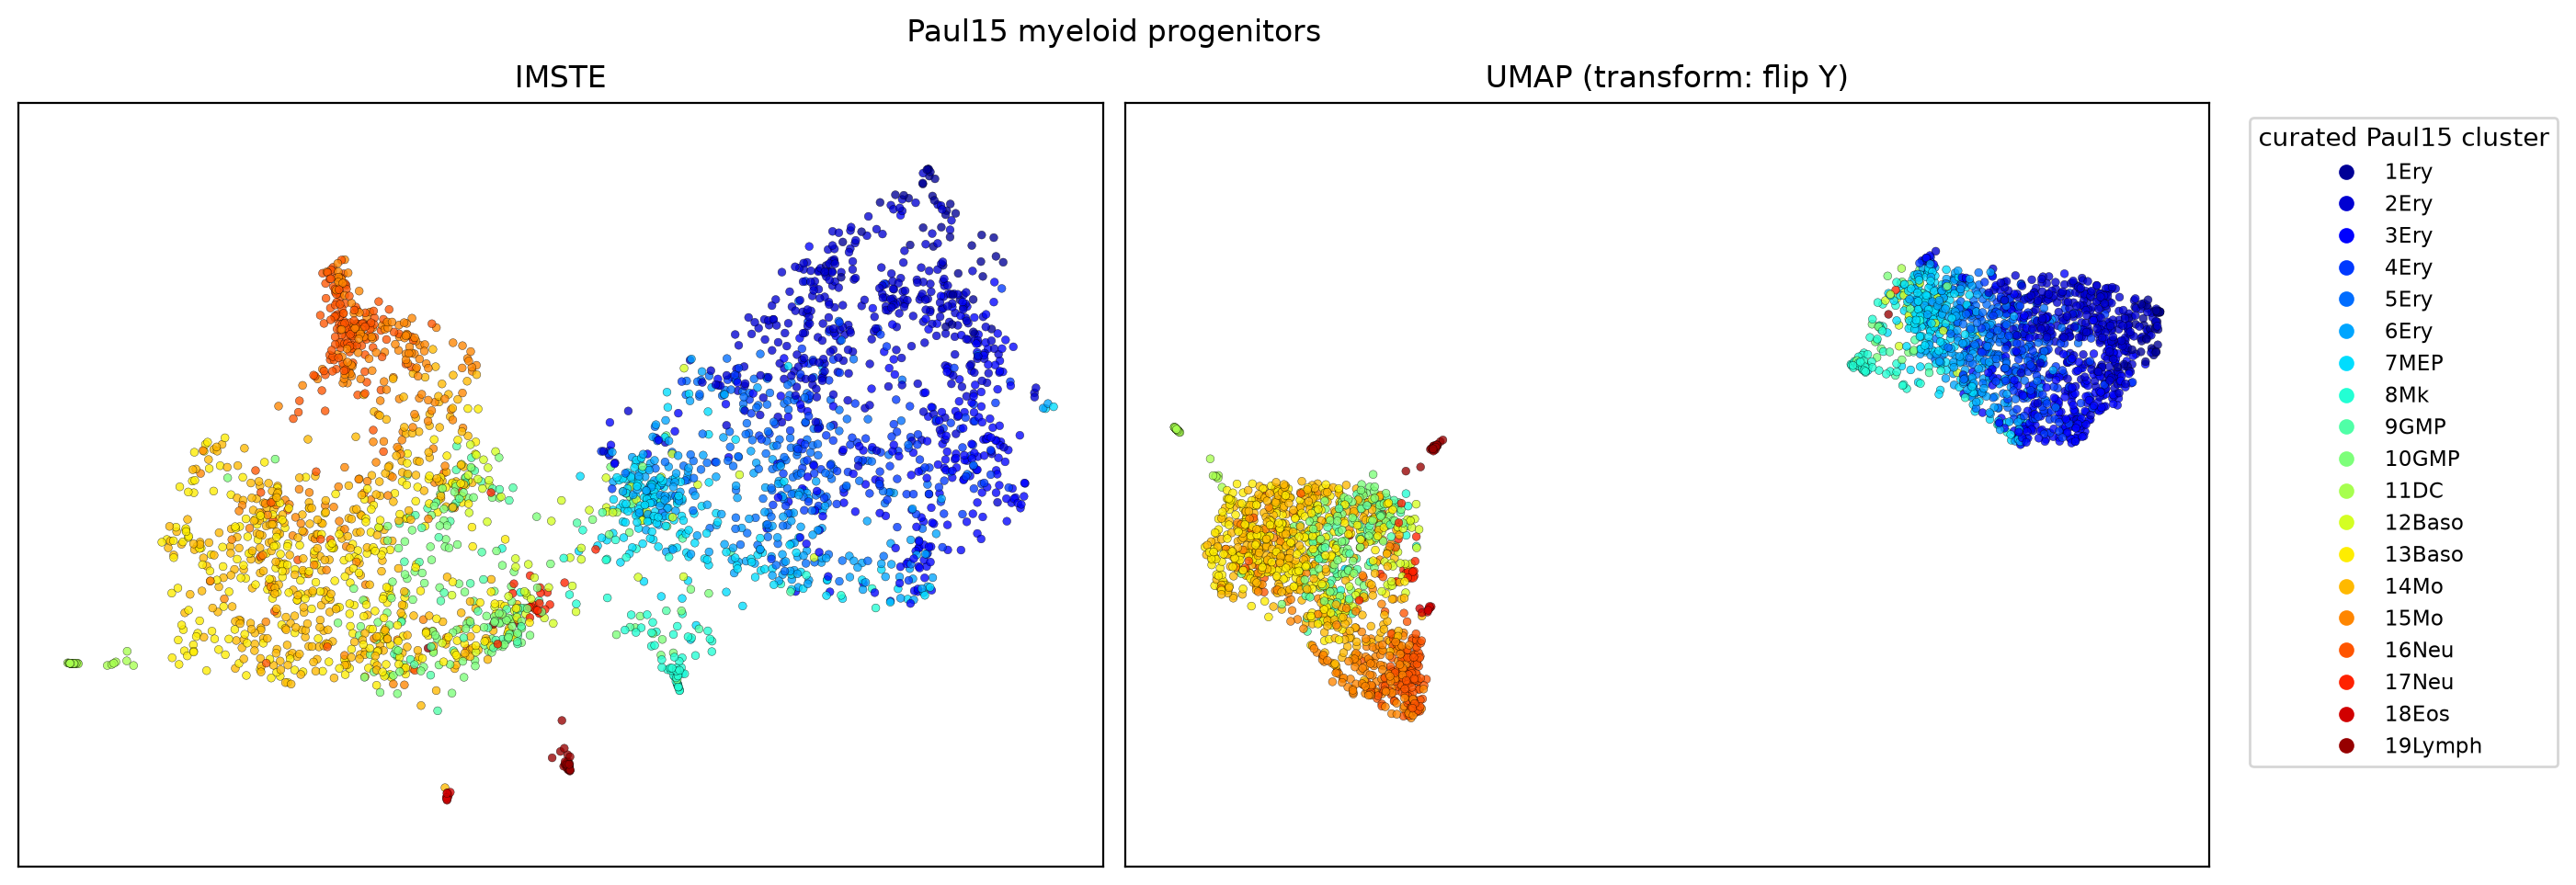

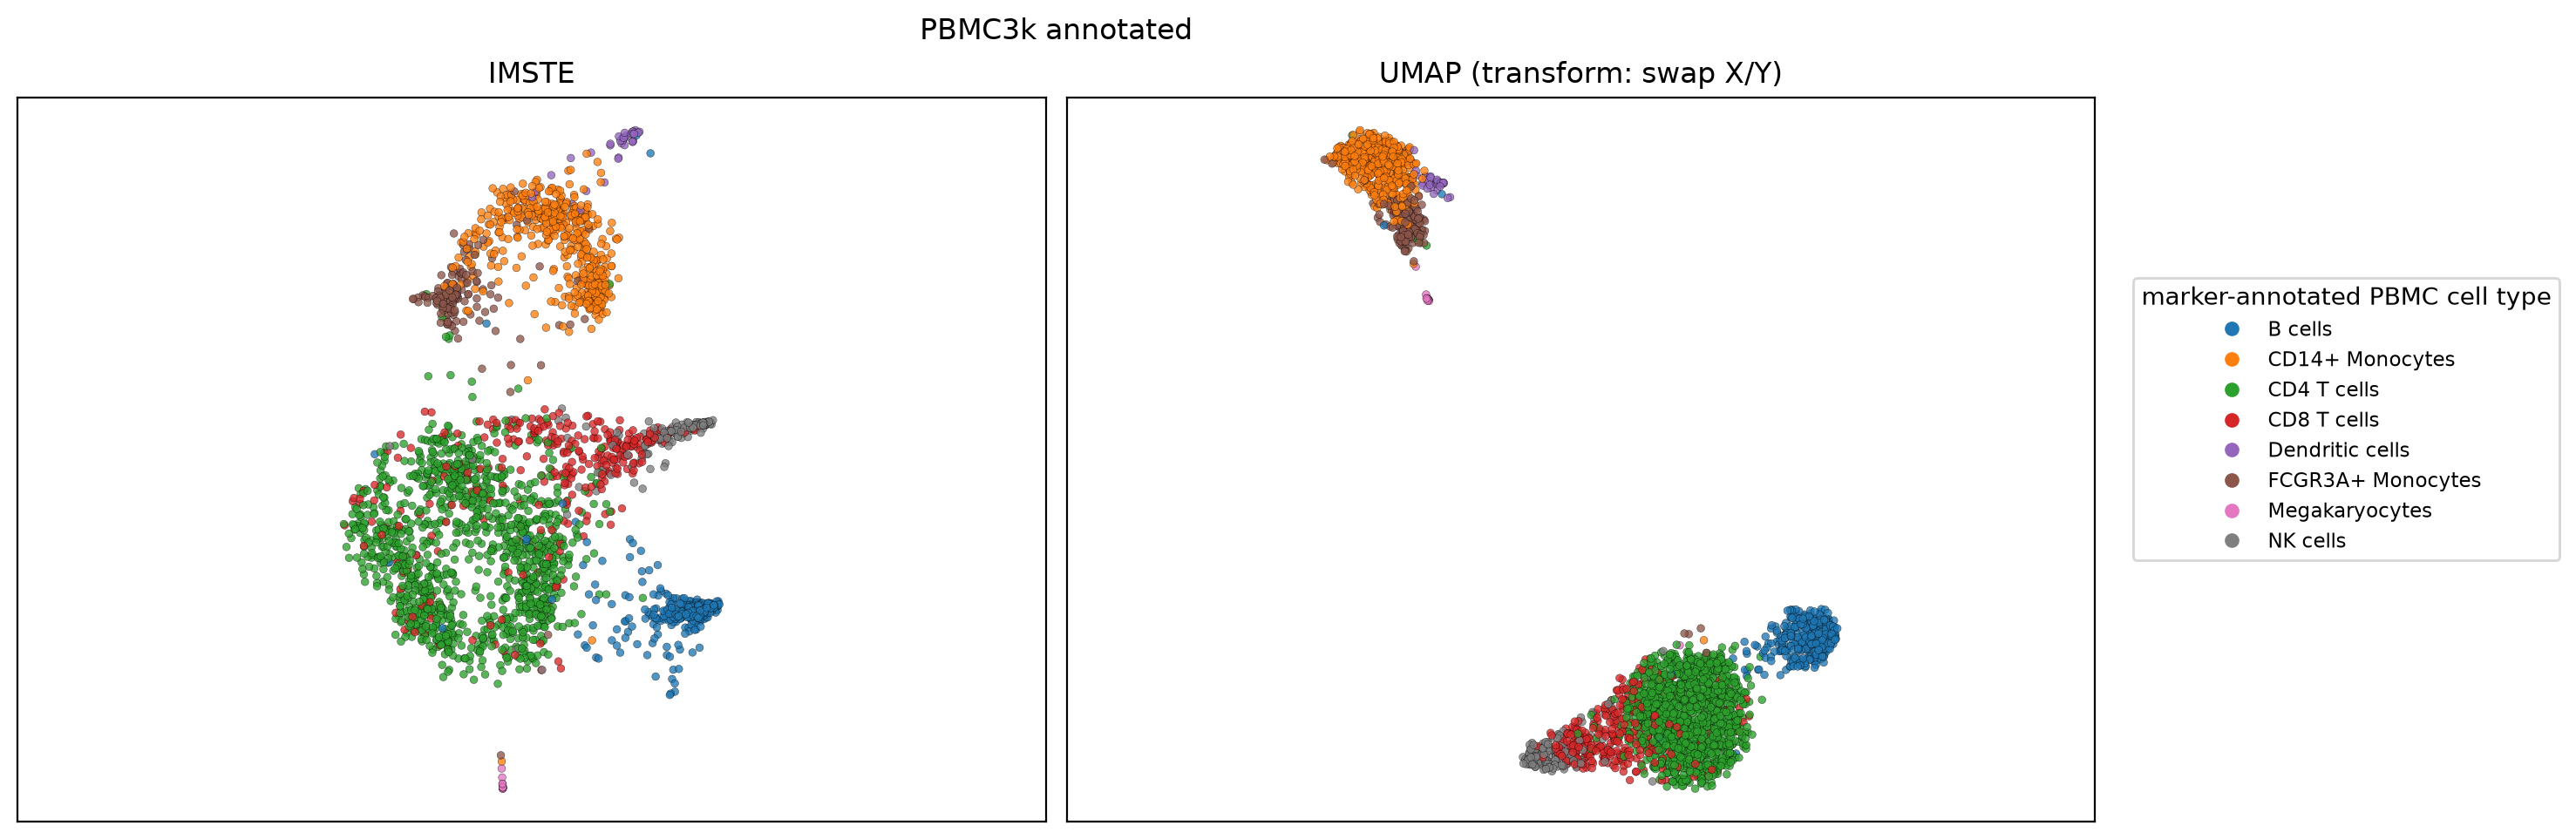

In [35]:
embedding_figures = plot_embedding_comparisons(datasets, embeddings, embedding_alignment)
for fig in embedding_figures.values():
    display(fig)
    plt.close(fig)

### Paul15 cell-fate stages

Paul15 now includes a broad, ordered stage annotation alongside its original cluster labels: progenitor clusters (MEP/GMP), differentiating lineage clusters (erythroid, basophil, monocyte, and neutrophil states), and specialized identities (megakaryocyte, dendritic, eosinophil, and lymphoid cells). This is a curated grouping for visualization, not measured pseudotime or a claim that all lineages follow one linear path. The panels reuse the embeddings above; labels are not supplied to either reducer.

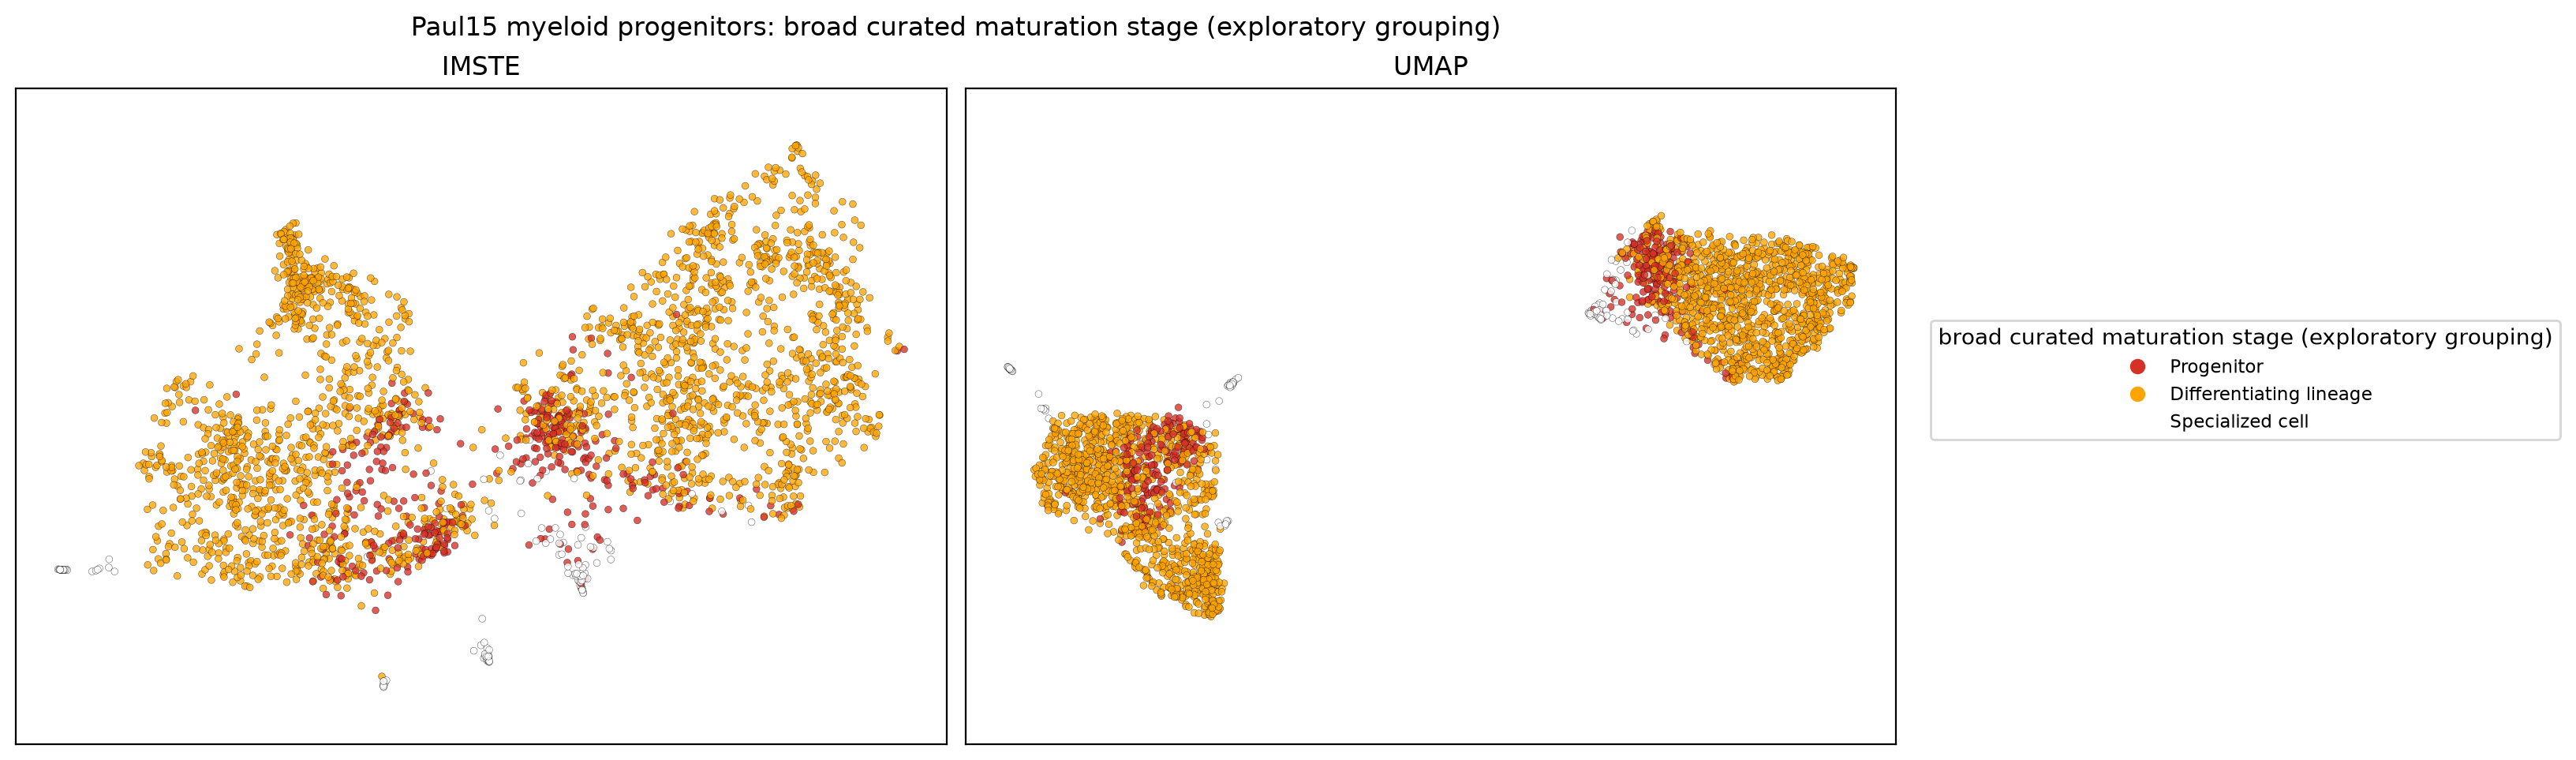

In [34]:
cell_fate_figures = plot_cell_fate_stages(datasets, embeddings)
_ = display(cell_fate_figures["Paul15 myeloid progenitors"])

### PBMC3k UMAP island diagnostic

The plot appears to contain a detached island. This check inspects connected components in UMAP’s fuzzy neighbor graph and reports the cell-type mixture of each component. It helps distinguish an actually disconnected graph component from a group that only looks detached after 2D layout.

In [22]:
pbmc_data = datasets["PBMC3k annotated"]
_, pbmc_umap_graph_components = diagnose_umap_graph(
    pbmc_data["X"], pbmc_data["labels"], umap_params=UMAP_PARAMS
)
pbmc_umap_graph_components

,graph_component,cells,fraction,number_of_labels,largest_label_share,most_common_labels
0,0,2638,1.0,8,0.433662,"((CD4 T cells, 0.434), (CD14+ Monocytes, 0.182..."


This diagnostic checks whether visually separated regions correspond to disconnected components in the UMAP neighbor graph. The embedding now follows the standard HVG-to-PCA path, and both reducers receive the same PCs. A visual island can still occur within one connected graph component, so use the component sizes together with the plot when interpreting apparent separations.

## Class-mixture MST graph overlays

Use the reusable `imste.class_graph.plot_class_mixture_mst` function on each dataset. Each method gets up to three full-covariance Gaussian components per annotated cell population. The plot connects component centers with two iterated MSTs and omits same-class edges. For each remaining edge, the two endpoint Gaussian densities form an equal-prior pairwise posterior, evaluated on the other component’s assigned samples in that 2D embedding. The directional probabilities are averaged; chance-level overlap (0.5) is fully opaque, and sets black-edge opacity.

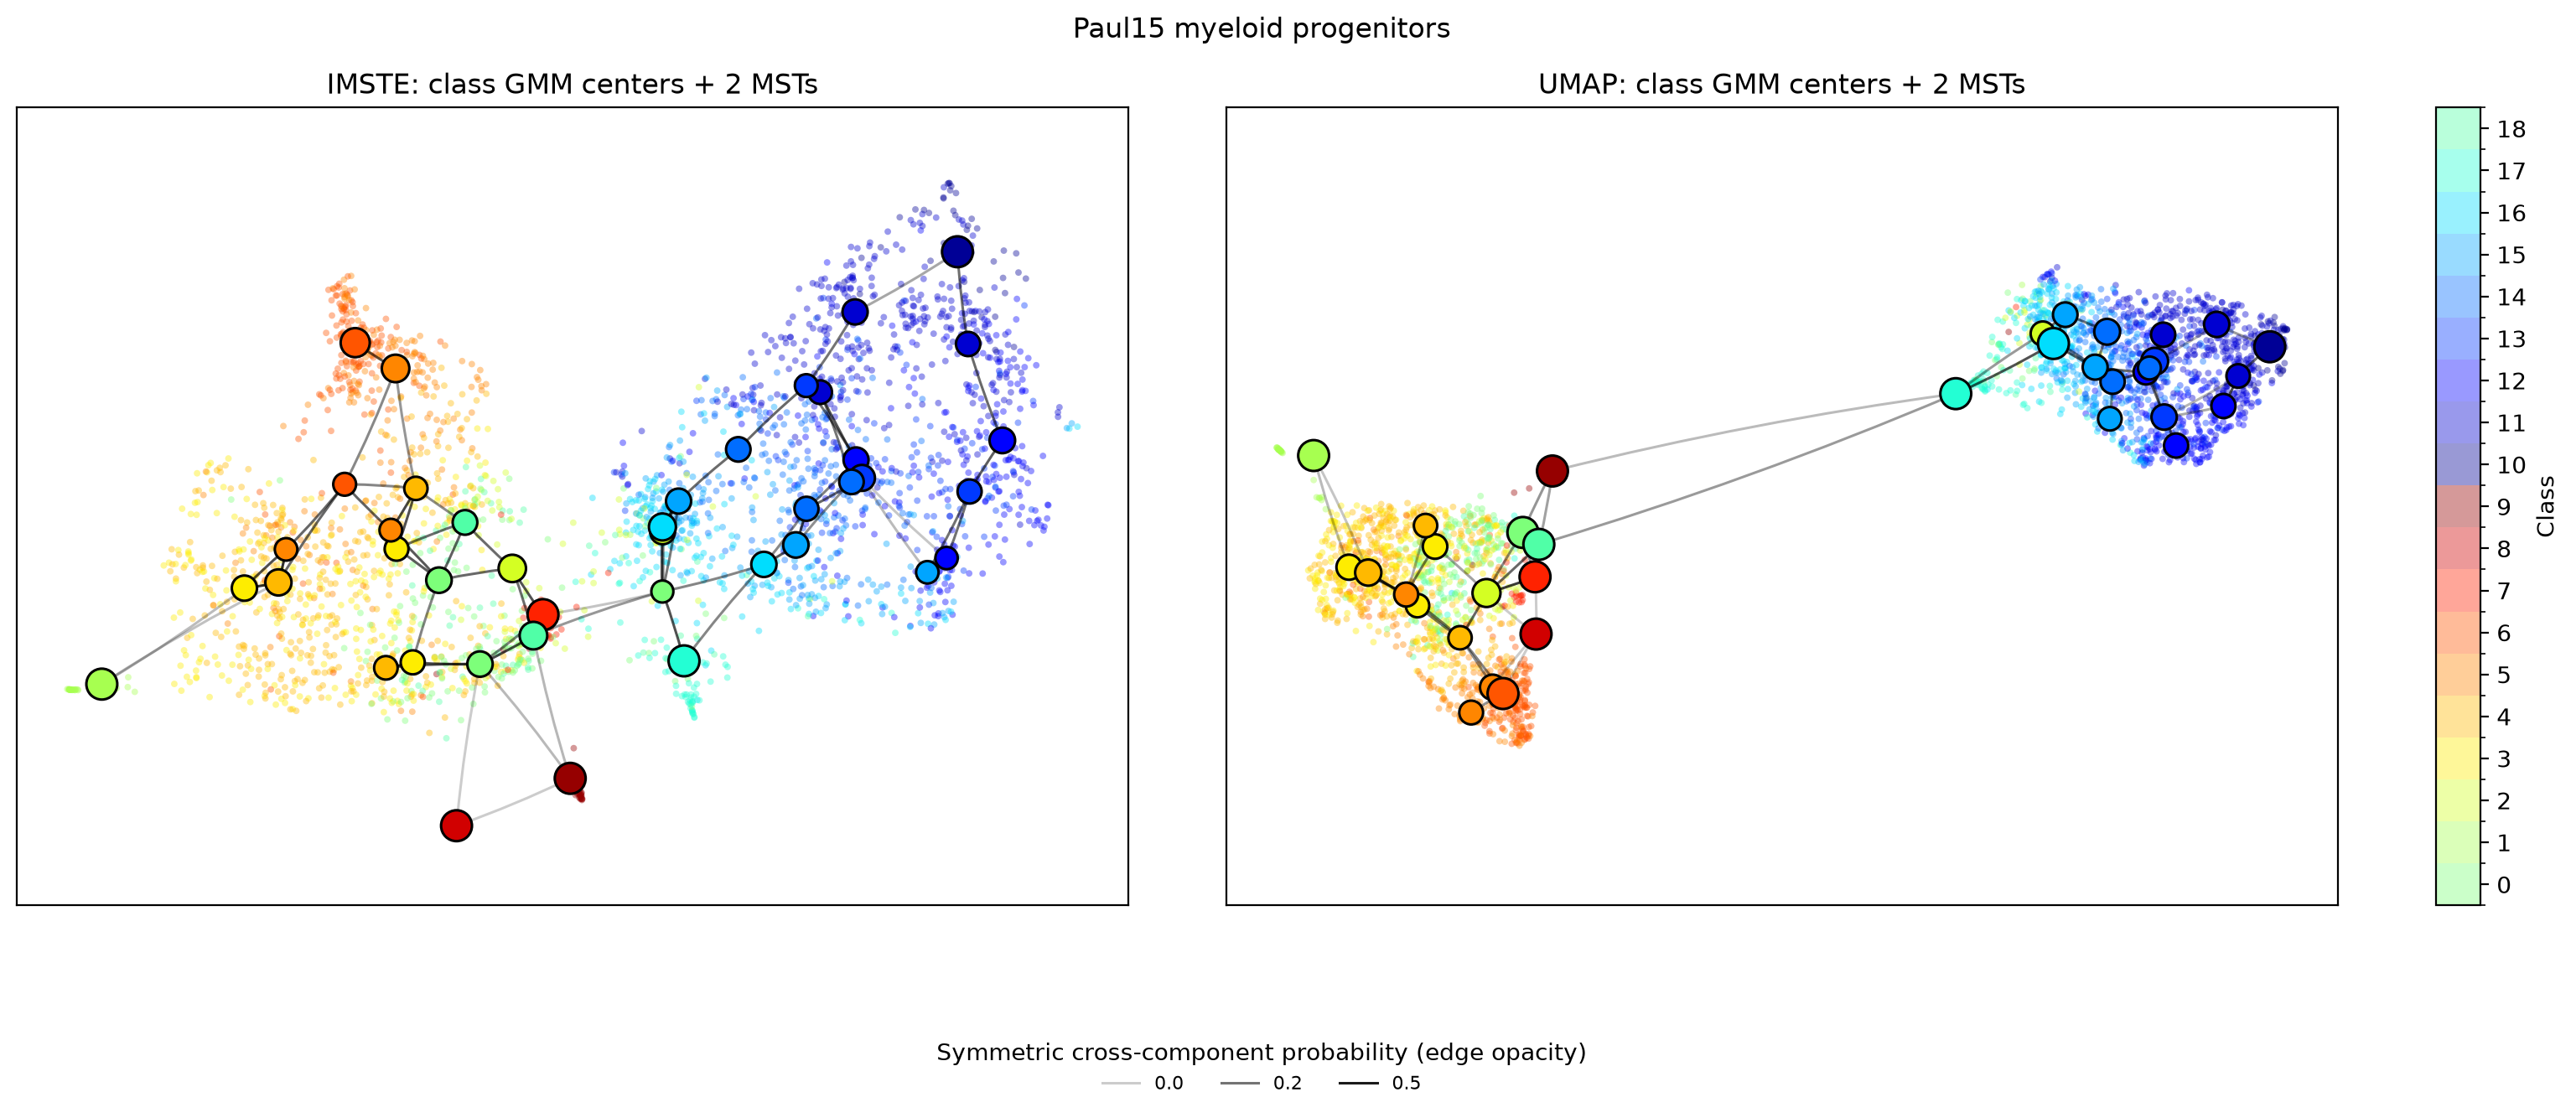

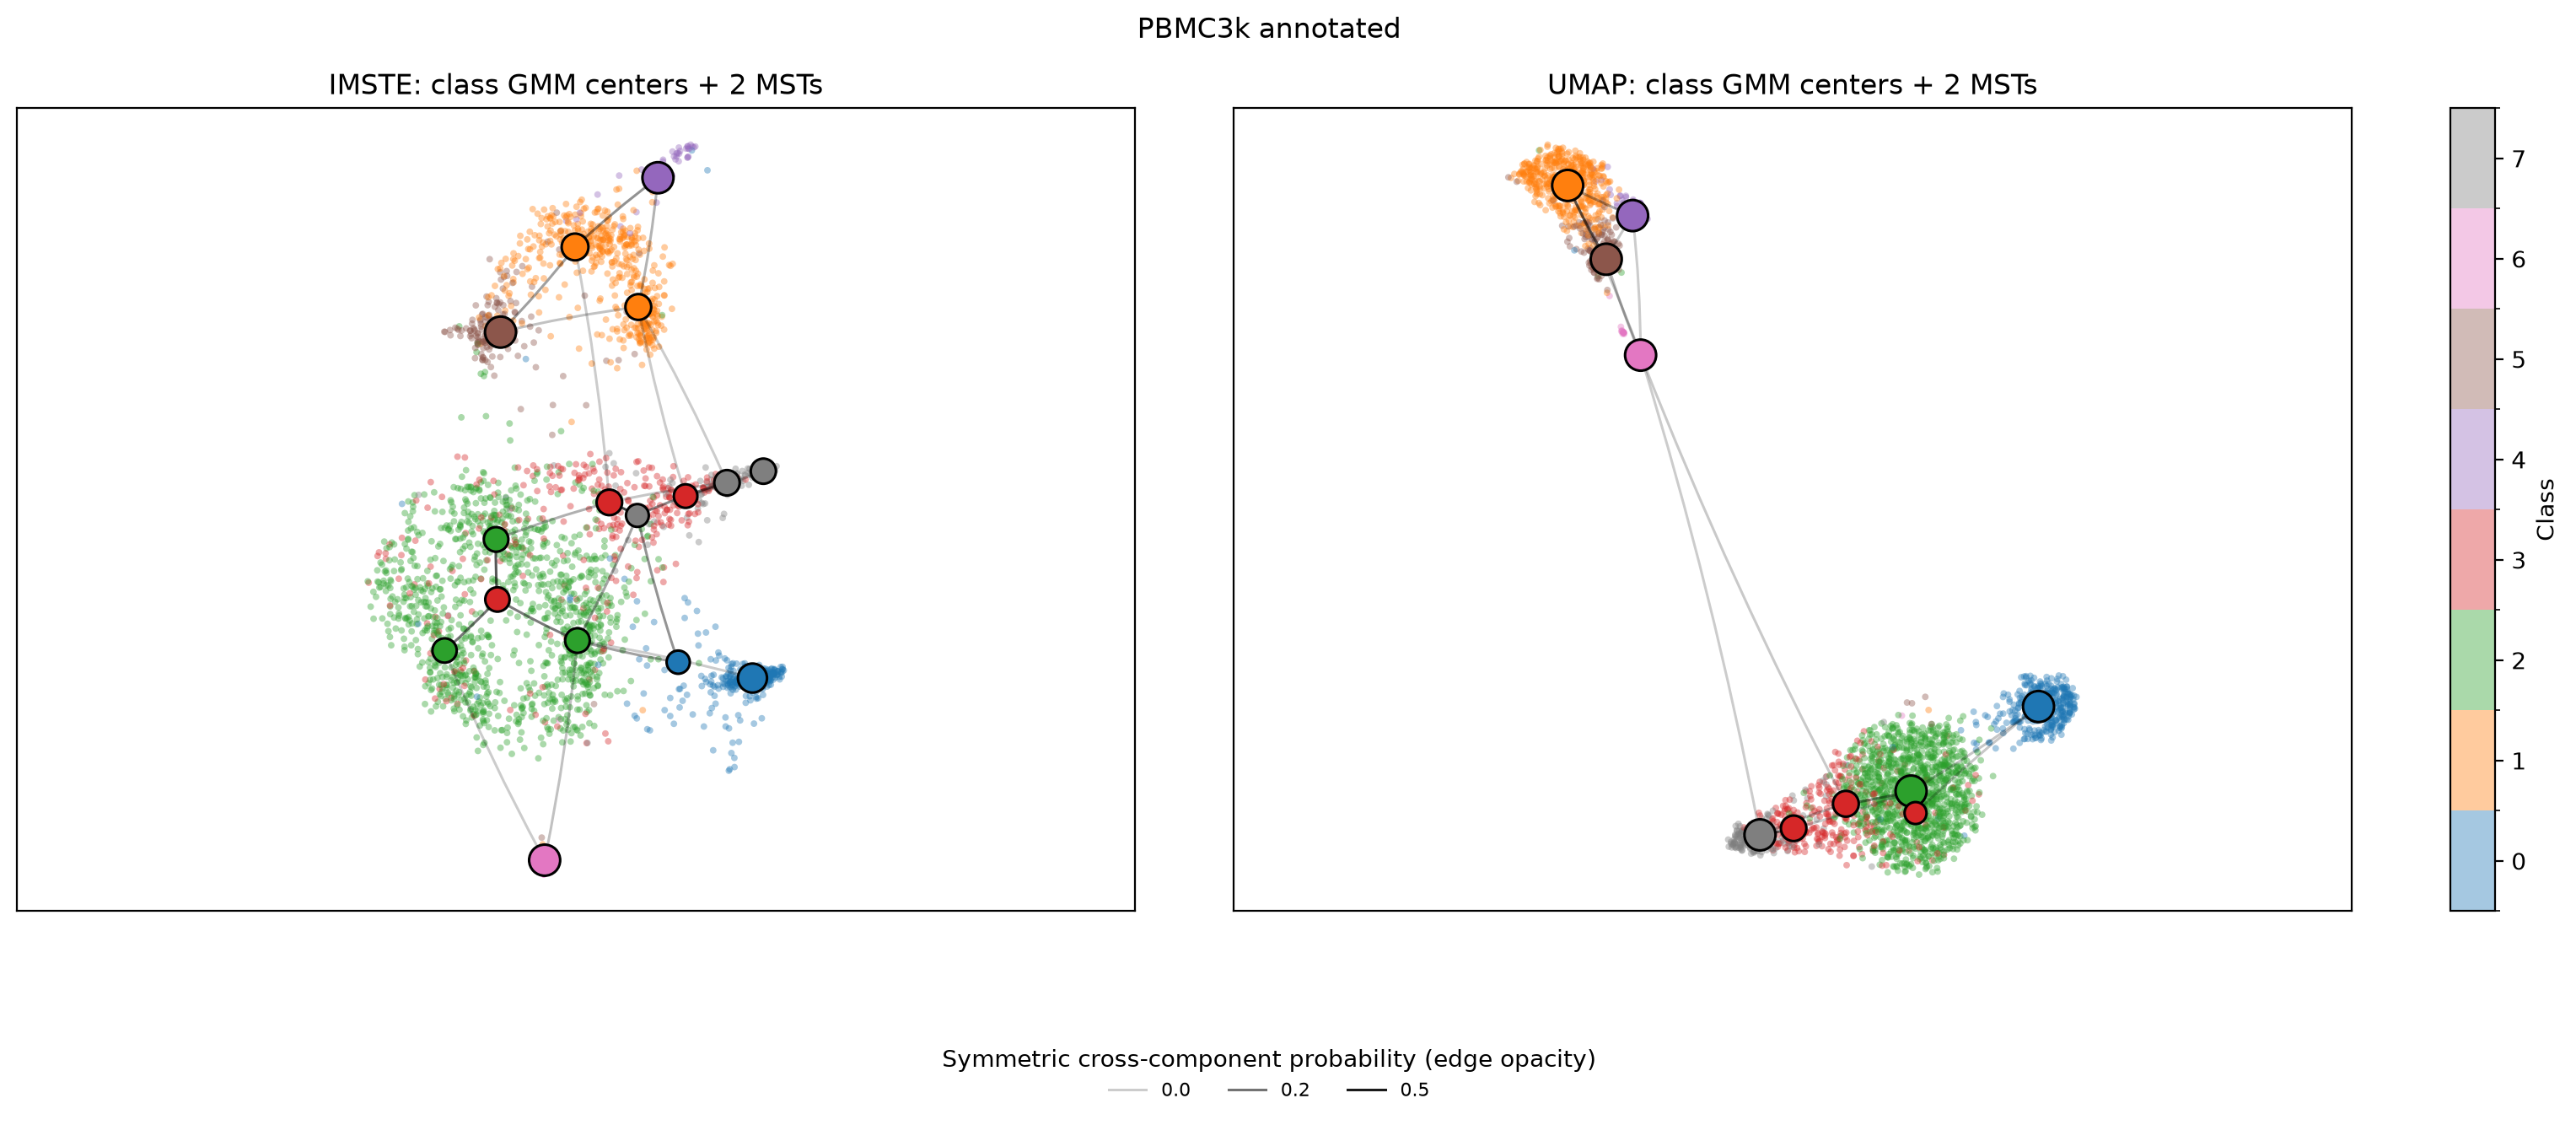

edges  mean_edge_alpha
dataset                    embedding                        
PBMC3k annotated           IMSTE         22         0.360895
                           UMAP          15         0.329216
Paul15 myeloid progenitors IMSTE         71         0.561891
                           UMAP          60         0.525460

In [23]:
class_graph_figures, biological_class_graph_edges = plot_biological_class_graphs(
    datasets, embeddings, point_alpha=GRAPH_POINT_ALPHA, random_state=RANDOM_STATE
)
for fig in class_graph_figures.values():
    display(fig)
    plt.close(fig)
biological_class_graph_edges.groupby(["dataset", "embedding"]).agg(
    edges=("edge_alpha", "size"), mean_edge_alpha=("edge_alpha", "mean")
)

## Which class-pair relations are unique to each embedding?

Collapse the component-level MST edges to unordered label pairs, then list pairs present in one graph but absent from the other. The ranking uses mean chance-normalized 2D component overlap; it says how confused an edge looks in its own embedding, not whether the biology is correct.

We also check a small, pre-specified set of PBMC relationships: CD4 and CD8 T-cell types; CD14+ and FCGR3A+ monocyte types; and CD8 T cells and NK cells as related cytotoxic lymphocyte populations. These checks come from the marker-based Scanpy annotations and broad lineage/function knowledge, so they are a modest validation set rather than a complete biological gold standard.

In [24]:
biological_relation_differences, expected_relation_results, expected_relation_summary = (
    compare_biological_class_relations(
        biological_class_graph_edges,
        {name: data["labels"] for name, data in datasets.items()},
    )
)
for name, table in biological_relation_differences.items():
    print(f"{name}: IMSTE-only and UMAP-only class pairs")
    display(table)
display(expected_relation_results)
display(expected_relation_summary)

Paul15 myeloid progenitors: IMSTE-only and UMAP-only class pairs


,rank,class_a,class_b,present_in,missing_from,edge_error,max_component_edge_error,n_component_edges,component_edges
0,1,10GMP,8Mk,IMSTE,UMAP,6.969320e-01,6.969320e-01,1,"((0, 0, 0.696932),)"
1,2,10GMP,15Mo,IMSTE,UMAP,6.521048e-01,6.521048e-01,1,"((1, 2, 0.652105),)"
2,3,10GMP,13Baso,IMSTE,UMAP,5.591372e-01,6.358293e-01,3,"((1, 1, 0.633681), (1, 2, 0.407901), (2, 2, 0...."
3,4,10GMP,14Mo,IMSTE,UMAP,5.500549e-01,5.500549e-01,1,"((2, 2, 0.550055),)"
4,5,13Baso,9GMP,IMSTE,UMAP,5.352889e-01,5.352889e-01,1,"((1, 0, 0.535289),)"
5,6,10GMP,6Ery,IMSTE,UMAP,4.657761e-01,4.657761e-01,1,"((0, 0, 0.465776),)"
6,7,10GMP,7MEP,IMSTE,UMAP,4.634431e-01,5.283704e-01,2,"((0, 0, 0.52837), (0, 1, 0.398516))"
7,8,5Ery,7MEP,IMSTE,UMAP,3.850028e-01,3.850028e-01,1,"((0, 1, 0.385003),)"
8,9,14Mo,9GMP,IMSTE,UMAP,3.666147e-01,3.666147e-01,1,"((1, 0, 0.366615),)"
9,10,4Ery,6Ery,IMSTE,UMAP,3.023181e-01,5.087427e-01,2,"((1, 1, 0.508743), (2, 1, 0.095893))"


PBMC3k annotated: IMSTE-only and UMAP-only class pairs


,rank,class_a,class_b,present_in,missing_from,edge_error,max_component_edge_error,n_component_edges,component_edges
0,1,B cells,NK cells,IMSTE,UMAP,0.312217,0.312217,1,"((1, 1, 0.312217),)"
1,2,CD4 T cells,NK cells,IMSTE,UMAP,0.222749,0.222749,1,"((0, 1, 0.222749),)"
2,3,CD4 T cells,Megakaryocytes,IMSTE,UMAP,0.031459,0.060724,2,"((0, 0, 0.060724), (1, 0, 0.002194))"
3,4,CD14+ Monocytes,CD8 T cells,IMSTE,UMAP,0.000076,0.000149,2,"((0, 2, 0.000003), (1, 1, 0.000149))"
4,5,CD14+ Monocytes,NK cells,IMSTE,UMAP,0.000007,0.000007,1,"((1, 2, 0.000007),)"
5,1,FCGR3A+ Monocytes,Megakaryocytes,UMAP,IMSTE,0.100042,0.100042,1,"((0, 0, 0.100042),)"
6,2,CD14+ Monocytes,Megakaryocytes,UMAP,IMSTE,0.035329,0.035329,1,"((0, 0, 0.035329),)"
7,3,B cells,CD8 T cells,UMAP,IMSTE,0.027612,0.027612,1,"((0, 1, 0.027612),)"
8,4,Dendritic cells,FCGR3A+ Monocytes,UMAP,IMSTE,0.027250,0.027250,1,"((0, 0, 0.02725),)"
9,5,CD8 T cells,Megakaryocytes,UMAP,IMSTE,0.015296,0.015296,1,"((2, 0, 0.015296),)"


,dataset,relationship,class_a,class_b,IMSTE_edge_present,IMSTE_mean_edge_error,UMAP_edge_present,UMAP_mean_edge_error
0,Paul15 myeloid progenitors,erythroid states,1Ery,2Ery,True,0.365747,True,0.389240
1,Paul15 myeloid progenitors,erythroid states,1Ery,3Ery,False,NaN,False,NaN
2,Paul15 myeloid progenitors,erythroid states,1Ery,4Ery,False,NaN,False,NaN
3,Paul15 myeloid progenitors,erythroid states,1Ery,5Ery,False,NaN,False,NaN
4,Paul15 myeloid progenitors,erythroid states,1Ery,6Ery,False,NaN,False,NaN
5,Paul15 myeloid progenitors,erythroid states,2Ery,3Ery,True,0.609360,True,0.678151
6,Paul15 myeloid progenitors,erythroid states,2Ery,4Ery,True,0.688123,True,0.327781
7,Paul15 myeloid progenitors,erythroid states,2Ery,5Ery,True,0.480565,True,0.676766
8,Paul15 myeloid progenitors,erythroid states,2Ery,6Ery,False,NaN,False,NaN
9,Paul15 myeloid progenitors,erythroid states,3Ery,4Ery,True,0.472643,True,0.554469


,expected_relations,IMSTE_hits,UMAP_hits
dataset,,,
PBMC3k annotated,3,3,3
Paul15 myeloid progenitors,26,15,14


The following summaries compare global positioning with distances in the same configured HVG input matrices. They are complementary to the class-pair graph checks above, not independent biological truth.

In [25]:
metrics = global_position_metrics(datasets, embeddings, seed=RANDOM_STATE)
metrics

,dataset,method,pairwise cell-distance rho,population-centroid distance rho,population-centroid distance tau,nearest-population overlap@3
0,Paul15 myeloid progenitors,IMSTE,0.406085,0.592596,0.446715,0.701754
1,Paul15 myeloid progenitors,UMAP,0.416232,0.413706,0.315308,0.701754
2,PBMC3k annotated,IMSTE,0.370150,0.603175,0.449735,0.625000
3,PBMC3k annotated,UMAP,0.363477,0.255063,0.142857,0.708333


## UMAP neighborhood-size sensitivity

Compare the global-positioning measures across several UMAP settings instead of selecting a single neighborhood size.

In [26]:
umap_sensitivity = umap_sensitivity_metrics(
    datasets, seed=RANDOM_STATE, neighbors=(10, 20, 40)
)
umap_sensitivity

,dataset,UMAP n_neighbors,pairwise cell-distance rho,population-centroid distance rho,population-centroid distance tau,nearest-population overlap@3
0,Paul15 myeloid progenitors,10,0.423452,0.451739,0.342002,0.719298
1,Paul15 myeloid progenitors,20,0.422350,0.437641,0.333333,0.701754
2,Paul15 myeloid progenitors,40,0.416120,0.417633,0.315583,0.649123
3,PBMC3k annotated,10,0.390273,0.602627,0.439153,0.708333
4,PBMC3k annotated,20,0.379624,0.291735,0.201058,0.708333
5,PBMC3k annotated,40,0.373493,0.269841,0.158730,0.708333


## Optional seed robustness

The main IMSTE result uses 1,000 epochs. Set `RUN_SEED_CHECKS=True` to fit two additional seeds; this repeats the IMSTE runs.

In [27]:
if RUN_SEED_CHECKS:
    seed_results = seed_robustness_metrics(
        datasets, seeds=(7, 123), n_epochs=N_EPOCHS, n_msts=5
    )
    display(seed_results)
else:
    print("Seed checks skipped. Set RUN_SEED_CHECKS=True to run them.")

Seed checks skipped. Set RUN_SEED_CHECKS=True to run them.


## Candidate interpretation

Treat the unique-edge rankings as discovery candidates. The expected-lineage table is a separate, pre-specified check: it asks whether each graph includes known same-lineage or related-cell-type pairs. A graph edge means adjacency among GMM component centers, while edge error measures overlap in the 2D embedding; neither alone establishes a biological relationship.

For PBMC3k, cell-type names are based on marker genes reported in the [Scanpy PBMC3k annotation tutorial](https://scanpy-tutorials.readthedocs.io/en/multiomics/pbmc3k.html). Paul15 lineage context is documented in the [Scanpy trajectory tutorial](https://scanpy.readthedocs.io/en/stable/tutorials/trajectories/paga-paul15.html). These annotations support a small set of expected relationships, not a comprehensive ground-truth graph.